# 16. Evaluación ampliada: otros conjuntos, robustez, semillas, sensibilidad, interpretabilidad, equidad y costo

El capítulo 13 evaluó DES-CPL en el problema principal. La guía pide además, en sus secciones 6.2, 6.3 y 6.6:
- evaluar el modelo y los benchmarks en al menos **tres conjuntos de datos adicionales**, con una prueba entre conjuntos;
- reportar la **varianza por semilla** con al menos diez semillas;
- estudiar la **robustez** frente a ruido, desbalance y tamaño de muestra;
- estudiar la **sensibilidad** a los hiperparámetros;
- aplicar **SHAP** al modelo original, auditar su **equidad** por subgrupo y reportar el **presupuesto y los tiempos** de cada modelo;
- completar las pruebas de hipótesis con la **prueba exacta de McNemar** y la **t bayesiana correlacionada**, que pide la guía de redacción del artículo.

Todo sigue el protocolo pre-registrado (`experiments/protocolo.md`, etiqueta `protocolo-v1`). Las desviaciones están declaradas en 16.1.

Los resultados se calcularon con dos scripts, y este capítulo solo los lee:
- `experiments/conjuntos_adicionales.py` → `results/adicionales/`;
- `experiments/semillas_robustez.py` → `results/robustez_des_cpl.csv`, `semillas_des_cpl.csv` y `sensibilidad_des_cpl.csv`;
- `experiments/artefacto_des_cpl.py` → `artifacts/shap_global.parquet`, `artifacts/predicciones_prueba.parquet` y `results/presupuesto_tiempos.csv`.

In [1]:
from config import *
from IPython.display import display

from src.estadistica import correccion_holm, delta_cliff, diferencia_critica, prueba_nadeau_bengio

BENCHMARKS = ["logistica", "bayes", "knn", "arbol", "random_forest", "xgboost", "svm",
              "lightgbm", "catboost"]
ESTATICOS = ["Promedio simple", "Apilamiento logístico", "Pesos globales (Brier)"]
METODOS = BENCHMARKS + ESTATICOS + ["DES-CPL"]
NOMBRES = {"diabetes": "Diabetes 130-US (principal)", "credito": "Crédito (Taiwán)",
           "banco": "Bank Marketing", "cdc": "CDC Diabetes"}

# Problema principal: 7 base, ensambles y DES-CPL (cap. 13) + LightGBM y CatBoost.
principal = pd.read_csv(RESULTADOS / "des_cpl_evaluacion_60.csv")
principal = pd.concat([
    principal[principal["método"].isin(METODOS)][["fold", "método", "auc_pr", "auc_roc", "brier"]],
    pd.read_csv(RESULTADOS / "benchmarks_sota.csv").rename(columns={"modelo": "método"})
    [["fold", "método", "auc_pr", "auc_roc", "brier"]],
]).assign(conjunto="diabetes")
adicionales = pd.read_csv(RESULTADOS / "adicionales" / "evaluacion_conjuntos.csv")
todo = pd.concat([principal, adicionales[["conjunto", "fold", "método", "auc_pr", "auc_roc", "brier"]]],
                 ignore_index=True)
CONJUNTOS = ["diabetes", "credito", "banco", "cdc"]
print(todo.groupby("conjunto")["fold"].nunique().to_dict(), "folds por conjunto;",
      todo["método"].nunique(), "métodos")

{'banco': 5, 'cdc': 5, 'credito': 5, 'diabetes': 5} folds por conjunto; 13 métodos


## 16.1. Conjuntos de datos adicionales

**Conjuntos.** Los tres se eligieron antes de conocer el desempeño del modelo, con los criterios del protocolo: clasificación binaria desbalanceada, fuente pública (UCI), y dominio y tamaño distintos.

| Conjunto | Registros | Variables | Positivos | Dominio |
|---|---|---|---|---|
| Default of Credit Card Clients (Yeh y Lien, 2009) | 30 000 | 23 | 22.1 % | Finanzas |
| Bank Marketing (Moro et al., 2014) | 45 211 | 15 | 11.7 % | Mercadeo |
| CDC Diabetes Health Indicators (BRFSS 2015) | 100 000 de 253 680 | 21 | 13.9 % | Salud poblacional |

**Procedimiento.** En cada conjunto y en cada uno de 5 folds externos estratificados (semilla 42):
- los 7 modelos base, con su balanceo del problema principal, y LightGBM y CatBoost buscan sus hiperparámetros con Random Search de **60 evaluaciones**;
- DES-CPL busca los suyos con **60 evaluaciones** de Optuna, igual que en el problema principal;
- se evalúan también los ensambles estáticos.

**Desviaciones declaradas,** todas por cómputo:
1. La búsqueda de hiperparámetros se hace sobre una submuestra estratificada de 5 000 registros del entrenamiento de cada fold. El capítulo 12 ya buscaba sobre un cuarto de los pacientes en los modelos costosos. El reajuste final usa todo el fold.
2. CDC se usa con una submuestra estratificada de 100 000 registros. La memoria de las regiones de competencia crece con $n\,k\,M'$ (capítulo 15).
3. Solo se evalúa la versión final de DES-CPL, sin ablaciones.
4. En Bank Marketing se eliminó `duration`, la duración de la llamada: se conoce solo después de la llamada y casi determina la respuesta, por lo que los autores del conjunto recomiendan excluirla. Además, las filas se barajan antes de partir; la sección 16.2 explica por qué.

In [2]:
resumen = (todo.groupby(["conjunto", "método"])["auc_pr"].agg(["mean", "std"])
           .unstack("conjunto").swaplevel(axis=1).sort_index(axis=1))
media = todo.groupby(["conjunto", "método"])["auc_pr"].mean().unstack("conjunto")[CONJUNTOS]
tabla_conjuntos = pd.DataFrame({
    NOMBRES[c]: [f"{resumen[(c, 'mean')][m]:.4f} ± {resumen[(c, 'std')][m]:.4f}" for m in METODOS]
    for c in CONJUNTOS}, index=METODOS)
tabla_conjuntos["rango medio"] = media.rank(ascending=False).mean(axis=1).loc[METODOS].round(2)
guardar_resultado(media, "evaluacion_ampliada_auc_pr_por_conjunto")
display(tabla_conjuntos.sort_values("rango medio"))

,Diabetes 130-US (principal),Crédito (Taiwán),Bank Marketing,CDC Diabetes,rango medio
Apilamiento logístico,0.2280 ± 0.0158,0.5590 ± 0.0035,0.4519 ± 0.0192,0.4272 ± 0.0018,2.00
Pesos globales (Brier),0.2286 ± 0.0170,0.5581 ± 0.0051,0.4504 ± 0.0196,0.4256 ± 0.0020,2.75
DES-CPL,0.2279 ± 0.0174,0.5578 ± 0.0050,0.4500 ± 0.0194,0.4258 ± 0.0024,3.75
lightgbm,0.2253 ± 0.0143,0.5566 ± 0.0056,0.4528 ± 0.0166,0.4250 ± 0.0046,4.00
catboost,0.2285 ± 0.0171,0.5565 ± 0.0030,0.4405 ± 0.0104,0.4236 ± 0.0036,5.00
random_forest,0.2237 ± 0.0186,0.5583 ± 0.0049,0.4442 ± 0.0166,0.4208 ± 0.0023,5.00
xgboost,0.2290 ± 0.0124,0.5393 ± 0.0071,0.4175 ± 0.0549,0.4199 ± 0.0062,6.00
Promedio simple,0.2185 ± 0.0131,0.5438 ± 0.0028,0.4369 ± 0.0149,0.4157 ± 0.0038,7.50
logistica,0.2109 ± 0.0123,0.5042 ± 0.0060,0.4054 ± 0.0078,0.4019 ± 0.0049,9.75
svm,0.2145 ± 0.0133,0.5006 ± 0.0066,0.4031 ± 0.0096,0.4018 ± 0.0044,10.25


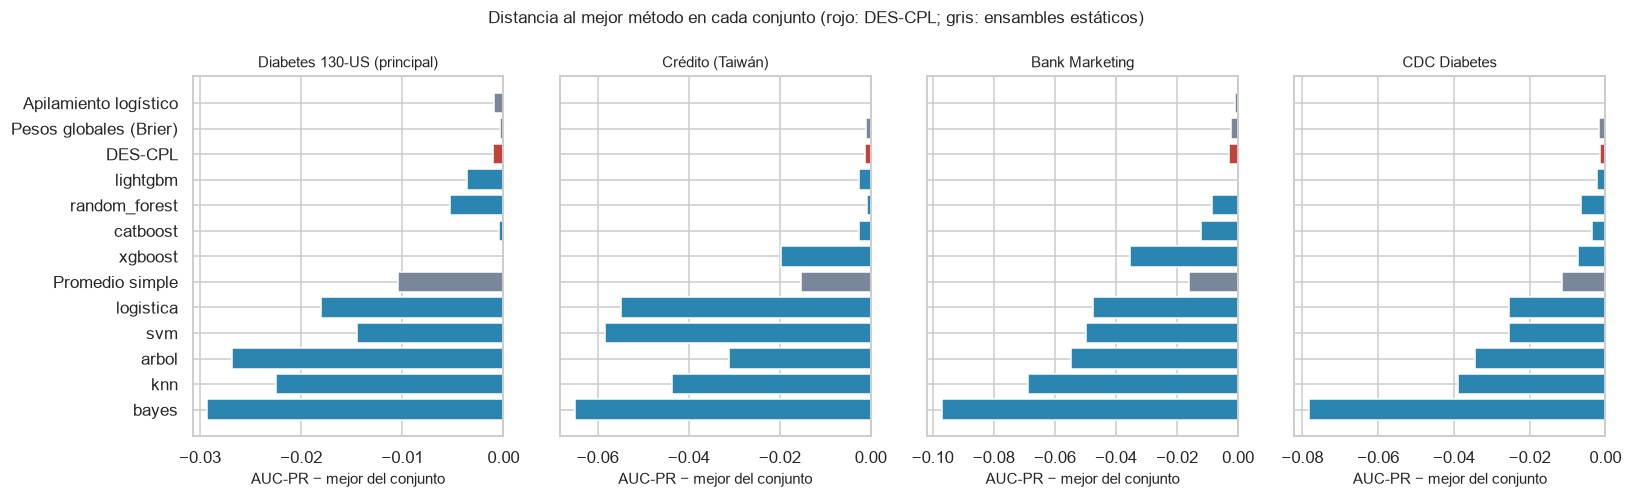

In [3]:
fig, ejes = plt.subplots(1, 4, figsize=(15, 4.6), sharey=True)
orden = media.rank(ascending=False).mean(axis=1).sort_values().index
for eje, c in zip(ejes, CONJUNTOS):
    dif = (media[c] - media[c].max()).loc[orden]
    colores = ["#C1443C" if m == "DES-CPL" else ("#7A869A" if m in ESTATICOS else "#2A86B0")
               for m in orden]
    eje.barh(range(len(orden)), dif, color=colores)
    eje.axvline(0, color="#1B2A4E", lw=0.8)
    eje.set_title(NOMBRES[c], fontsize=10)
    eje.set_xlabel("AUC-PR − mejor del conjunto")
ejes[0].set_yticks(range(len(orden)), orden)
ejes[0].invert_yaxis()
fig.suptitle("Distancia al mejor método en cada conjunto (rojo: DES-CPL; gris: ensambles estáticos)",
             fontsize=11)
plt.tight_layout()
plt.show()

### 16.1.1. Prueba entre conjuntos

El protocolo fija, para varios conjuntos:
- **Friedman con la corrección de Iman-Davenport** (Demšar, 2006), con cada conjunto como bloque y la AUC-PR media como medida;
- **Wilcoxon de rangos con signo, con Holm,** de DES-CPL frente a cada benchmark.

Con solo $N = 4$ conjuntos, el Wilcoxon unilateral no puede bajar de $p = 1/2^4 = 0.0625$. Por eso no puede rechazar a $\alpha = 0.05$ aunque DES-CPL ganara en los cuatro. Se reporta igual, porque lo pide el protocolo, y se complementa con la t de Nadeau-Bengio por conjunto, frente al mejor benchmark de cada uno.

In [4]:
from scipy import stats

rangos = media.loc[METODOS].rank(ascending=False)
k, N = len(METODOS), len(CONJUNTOS)
R = rangos.mean(axis=1)
chi2 = 12 * N / (k * (k + 1)) * (np.sum(R ** 2) - k * (k + 1) ** 2 / 4)
F_id = (N - 1) * chi2 / (N * (k - 1) - chi2)
p_chi2 = stats.chi2.sf(chi2, k - 1)
p_id = stats.f.sf(F_id, k - 1, (k - 1) * (N - 1))
cd = diferencia_critica(k, N)
print(f"Friedman: χ² = {chi2:.2f} (gl = {k - 1}), p = {p_chi2:.2e}")
print(f"Iman-Davenport: F = {F_id:.2f} (gl = {k - 1}, {(k - 1) * (N - 1)}), p = {p_id:.2e}")
print(f"Nemenyi: diferencia crítica = {cd:.2f} rangos; rango medio de DES-CPL = {R['DES-CPL']:.2f}")

filas = []
for b in BENCHMARKS + ESTATICOS:
    a, c = media.loc["DES-CPL"], media.loc[b]
    w = stats.wilcoxon(a, c, alternative="greater", zero_method="zsplit")
    filas.append({"comparación": f"DES-CPL vs {b}", "gana en conjuntos": int((a > c).sum()),
                  "dif. media": (a - c).mean(), "W": w.statistic, "p (unilateral)": w.pvalue,
                  "Δ de Cliff": delta_cliff(a.to_numpy(), c.to_numpy()),
                  "dif. de rango (Nemenyi)": R[b] - R["DES-CPL"]})
wilcoxon = pd.DataFrame(filas)
wilcoxon["p (Holm)"] = correccion_holm(wilcoxon["p (unilateral)"].to_numpy())
guardar_resultado(wilcoxon, "evaluacion_ampliada_wilcoxon")
display(wilcoxon.round(4))

Friedman: χ² = 41.70 (gl = 12), p = 3.74e-05
Iman-Davenport: F = 19.87 (gl = 12, 36), p = 2.29e-12
Nemenyi: diferencia crítica = 9.12 rangos; rango medio de DES-CPL = 3.75


,comparación,gana en conjuntos,dif. media,W,p (unilateral),Δ de Cliff,dif. de rango (Nemenyi),p (Holm)
0,DES-CPL vs logistica,4,0.0348,10.0,0.0625,0.375,6.00,0.75
1,DES-CPL vs bayes,4,0.0657,10.0,0.0625,0.375,9.25,0.75
2,DES-CPL vs knn,4,0.0418,10.0,0.0625,0.375,7.50,0.75
3,DES-CPL vs arbol,4,0.0352,10.0,0.0625,0.375,7.00,0.75
4,DES-CPL vs random_forest,3,0.0036,9.0,0.1250,0.125,1.25,0.75
5,DES-CPL vs xgboost,3,0.0140,9.0,0.1250,0.250,2.25,0.75
6,DES-CPL vs svm,4,0.0354,10.0,0.0625,0.375,6.50,0.75
7,DES-CPL vs lightgbm,3,0.0005,6.0,0.4375,0.125,0.25,1.00
8,DES-CPL vs catboost,3,0.0031,9.0,0.1250,0.125,1.25,0.75
9,DES-CPL vs Promedio simple,4,0.0117,10.0,0.0625,0.250,3.75,0.75


In [5]:
filas = []
for c in CONJUNTOS:
    por_fold = todo[todo["conjunto"] == c].pivot_table(index="fold", columns="método", values="auc_pr")
    mejor = por_fold[BENCHMARKS].mean().idxmax()
    dif = por_fold["DES-CPL"] - por_fold[mejor]
    nb = prueba_nadeau_bengio(dif.to_numpy())
    filas.append({"conjunto": NOMBRES[c], "mejor benchmark": mejor,
                  "AUC-PR mejor": por_fold[mejor].mean(), "AUC-PR DES-CPL": por_fold["DES-CPL"].mean(),
                  "dif.": dif.mean(), "gana en folds": f"{int((dif > 0).sum())}/5",
                  "t (Nadeau-Bengio)": nb["t"], "p (unilateral)": nb["p"],
                  "supera a XGBoost": por_fold["DES-CPL"].mean() > por_fold["xgboost"].mean()})
por_conjunto = pd.DataFrame(filas)
por_conjunto["p (Holm)"] = correccion_holm(por_conjunto["p (unilateral)"].to_numpy())
guardar_resultado(por_conjunto, "evaluacion_ampliada_por_conjunto")
display(por_conjunto.round(4))

,conjunto,mejor benchmark,AUC-PR mejor,AUC-PR DES-CPL,dif.,gana en folds,t (Nadeau-Bengio),p (unilateral),supera a XGBoost,p (Holm)
0,Diabetes 130-US (principal),xgboost,0.2290,0.2279,-0.0010,1/5,-0.2622,0.5969,False,1.0
1,Crédito (Taiwán),random_forest,0.5583,0.5578,-0.0005,1/5,-0.9591,0.8041,True,1.0
2,Bank Marketing,lightgbm,0.4528,0.4500,-0.0028,1/5,-1.2844,0.8658,True,1.0
3,CDC Diabetes,lightgbm,0.4250,0.4258,0.0009,2/5,0.2556,0.4054,True,1.0


**Lectura.**
- **Prueba global.** Friedman rechaza la igualdad de los 13 métodos con amplio margen (Iman-Davenport, $p \approx 10^{-12}$): el orden entre familias de modelos se repite en los cuatro conjuntos.
- **Posición de DES-CPL.** Es el tercero en rango medio (3.75), detrás de los dos ensambles estáticos fuertes: el apilamiento (2.00) y los pesos globales (2.75). Queda por delante de **todos** los benchmarks individuales: LightGBM 4.00, Random Forest y CatBoost 5.00, XGBoost 6.00. Es el mismo orden del problema principal, ahora visto en cuatro dominios.
- **Frente a cada mejor benchmark.** DES-CPL supera al mejor benchmark solo en CDC (+0.0008 sobre LightGBM). En crédito (Random Forest) y en Bank Marketing (LightGBM) queda por debajo. Ninguna diferencia es significativa (Nadeau-Bengio, $p \ge 0.40$).
- **Frente a XGBoost.** DES-CPL supera a XGBoost en los tres conjuntos adicionales. XGBoost es el mejor benchmark del problema principal, pero en los otros conjuntos queda muy atrás de los ensambles: hasta 0.035 por debajo del mejor en Bank Marketing.

**Condición 4 de superioridad del protocolo.** Pide ser mejor que el mejor benchmark en al menos dos de los tres conjuntos adicionales y no significativamente peor en ninguno. **No se cumple:** DES-CPL es mejor en uno de tres, aunque no es significativamente peor en ninguno. El veredicto de R3 sigue siendo negativo.

La lectura que sí sostienen los datos es otra: **combinar modelos es más estable entre dominios que elegir uno**. El mejor modelo individual cambia de un conjunto a otro (XGBoost, Random Forest, LightGBM), mientras que DES-CPL y los ensambles estáticos quedan siempre cerca de la cabeza. Ninguno de los tres combinadores se distingue de los otros. Para Nemenyi, la diferencia crítica es de 9.1 rangos con 4 conjuntos, así que solo separa los extremos.

## 16.2. Un hallazgo de la evaluación: el SVM en Bank Marketing

En la primera corrida, el SVM obtuvo en Bank Marketing un AUC-PR de **0.099**, por debajo de la prevalencia (0.117), es decir, peor que el azar. Sus probabilidades promediaban 0.226 en ambas clases: no distinguían nada.

**Causa.**
- El archivo de UCI está **ordenado por fecha de la campaña**, y la proporción de clientes que aceptan sube del 4 % en el primer tercio al 25 % en el último.
- El SVM es el único modelo con una validación interna que no baraja: la calibración de 3 pliegues que convierte sus puntajes en probabilidades (`CalibratedClassifierCV`).
- Con el archivo en orden, cada clasificador interno se entrenaba con unas épocas y se calibraba con otra. Las probabilidades resultantes quedaron sin relación con el riesgo.
- En el fold 0, la misma configuración da 0.112 con las filas en orden y 0.414 con las filas barajadas.

**Corrección.** Las filas de Bank Marketing se barajan con semilla 42 antes de partir, y el conjunto se volvió a calcular completo. El SVM pasó a 0.403, al nivel de la regresión logística. Los resultados descartados se conservan en `results/adicionales/banco_orden_original/` como evidencia. Crédito no tiene deriva a lo largo del archivo (22.6 %, 23.0 % y 20.8 % por tercio), y CDC ya entra barajado por el submuestreo.

**Lección para el proyecto.** Una validación interna sin barajar puede romper un modelo cuando los datos tienen orden temporal, sin dar ningún error: el modelo se entrena y predice normalmente. El problema principal también está ordenado por número de encuentro, y su SVM usa la misma calibración. Allí el efecto no aparece: el SVM rinde 0.2145, coherente con la regresión logística, porque la prevalencia de readmisión es estable en el tiempo. Pero es un riesgo que conviene declarar.

In [6]:
original = pd.read_csv(RESULTADOS / "adicionales" / "banco_orden_original" / "evaluacion.csv")
comparacion_banco = pd.DataFrame({
    "orden original (descartado)": original.groupby("método")["auc_pr"].mean(),
    "filas barajadas": adicionales.query("conjunto == 'banco'").groupby("método")["auc_pr"].mean(),
}).loc[METODOS]
comparacion_banco["cambio"] = comparacion_banco.iloc[:, 1] - comparacion_banco.iloc[:, 0]
display(comparacion_banco.round(4))

,orden original (descartado),filas barajadas,cambio
método,,,
logistica,0.4057,0.4054,-0.0003
bayes,0.3526,0.3558,0.0032
knn,0.3965,0.3840,-0.0125
arbol,0.3856,0.3981,0.0126
random_forest,0.4453,0.4442,-0.0011
xgboost,0.4128,0.4175,0.0047
svm,0.0993,0.4031,0.3038
lightgbm,0.4481,0.4528,0.0047
catboost,0.4489,0.4405,-0.0084


Solo el SVM cambia de forma sustancial. Los demás se mueven como máximo 0.013 (k-NN y árbol, en direcciones opuestas), que es lo esperable al cambiar la partición. DES-CPL apenas varía (de 0.4515 a 0.4500), porque su poda ya dejaba fuera al SVM. Los ensambles estáticos que lo incluían, como el promedio simple, sí mejoran al corregirlo.

## 16.3. Robustez

En cada uno de los 5 folds externos del problema principal se alteró **solo el entrenamiento**, y se evaluó en el fold de evaluación intacto. Los escenarios son:

| Escenario | Perturbación |
|---|---|
| `ruido_05`, `ruido_10` | Se invierte la etiqueta del 5 % y del 10 % de los encuentros de entrenamiento |
| `prevalencia_05` | Se descartan positivos hasta que sean el 5 % (en los datos originales son el 11.4 %) |
| `tamano_25`, `tamano_50` | Se entrena con el 25 % y el 50 % de los pacientes |

Los modelos base conservan los hiperparámetros del capítulo 12 en cada fold, sin volver a buscarlos. DES-CPL repite su búsqueda de 60 evaluaciones sobre su nuevo conjunto de selección. Así se aísla cómo responde cada método a la perturbación.

In [7]:
robustez = pd.read_csv(RESULTADOS / "robustez_des_cpl.csv")
referencia = principal.assign(escenario="original")[["escenario", "fold", "método", "auc_pr"]]
rob = pd.concat([referencia, robustez[["escenario", "fold", "método", "auc_pr"]]])
ESCENARIOS = ["original", "ruido_05", "ruido_10", "prevalencia_05", "tamano_50", "tamano_25"]
FOCO = ["DES-CPL", "Pesos globales (Brier)", "Apilamiento logístico", "xgboost", "random_forest",
        "logistica"]
tabla_rob = rob.pivot_table(index="método", columns="escenario", values="auc_pr").loc[FOCO, ESCENARIOS]
perdida = tabla_rob.sub(tabla_rob["original"], axis=0).drop(columns="original")
guardar_resultado(tabla_rob, "robustez_auc_pr")
display(tabla_rob.round(4))
print("Pérdida respecto de los datos originales:")
display(perdida.round(4))

filas = []
for e in ESCENARIOS[1:]:
    a = robustez.query("escenario == @e").pivot_table(index="fold", columns="método", values="auc_pr")
    dif = a["DES-CPL"] - a["xgboost"]
    nb = prueba_nadeau_bengio(dif.to_numpy())
    filas.append({"escenario": e, "DES-CPL − XGBoost": dif.mean(), "gana en folds": f"{int((dif > 0).sum())}/5",
                  "t": nb["t"], "p (unilateral)": nb["p"]})
rob_pruebas = pd.DataFrame(filas)
rob_pruebas["p (Holm)"] = correccion_holm(rob_pruebas["p (unilateral)"].to_numpy())
display(rob_pruebas.round(4))

escenario,original,ruido_05,ruido_10,prevalencia_05,tamano_50,tamano_25
método,,,,,,
DES-CPL,0.2279,0.2233,0.2206,0.2197,0.2195,0.2115
Pesos globales (Brier),0.2286,0.2227,0.2203,0.2198,0.2193,0.2126
Apilamiento logístico,0.2280,0.2232,0.2207,0.2206,0.2192,0.2128
xgboost,0.2290,0.2204,0.2148,0.2155,0.2148,0.1998
random_forest,0.2237,0.2214,0.2203,0.2202,0.2186,0.2100
logistica,0.2109,0.2120,0.2113,0.2090,0.2084,0.2048


Pérdida respecto de los datos originales:


escenario,ruido_05,ruido_10,prevalencia_05,tamano_50,tamano_25
método,,,,,
DES-CPL,-0.0046,-0.0073,-0.0082,-0.0084,-0.0165
Pesos globales (Brier),-0.0059,-0.0083,-0.0088,-0.0093,-0.0160
Apilamiento logístico,-0.0048,-0.0073,-0.0074,-0.0089,-0.0152
xgboost,-0.0085,-0.0141,-0.0135,-0.0141,-0.0292
random_forest,-0.0023,-0.0035,-0.0035,-0.0051,-0.0137
logistica,0.0011,0.0004,-0.0019,-0.0025,-0.0061


,escenario,DES-CPL − XGBoost,gana en folds,t,p (unilateral),p (Holm)
0,ruido_05,0.0028,2/5,0.8824,0.2137,0.3267
1,ruido_10,0.0058,4/5,1.4713,0.1076,0.3267
2,prevalencia_05,0.0042,5/5,1.2498,0.1398,0.3267
3,tamano_50,0.0047,4/5,1.7052,0.0817,0.3267
4,tamano_25,0.0117,5/5,2.7341,0.0261,0.1306


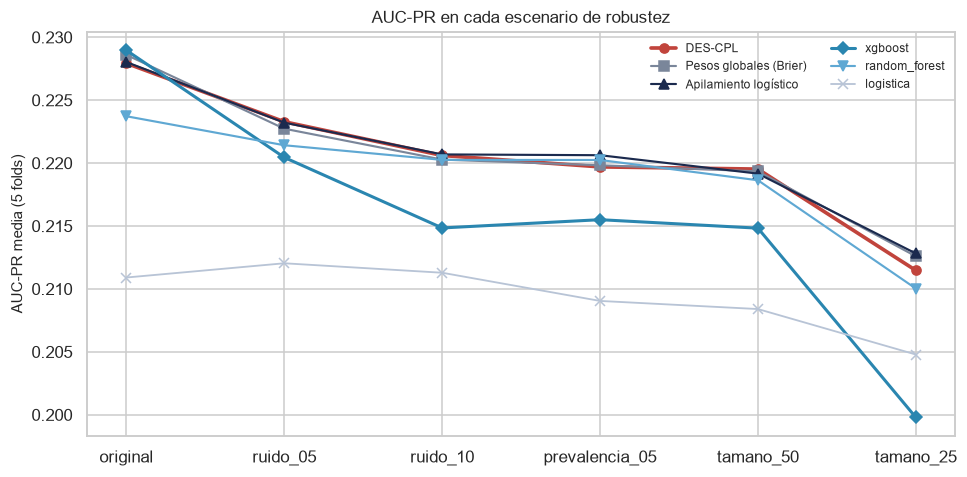

In [8]:
fig, eje = plt.subplots(figsize=(9, 4.5))
x = np.arange(len(ESCENARIOS))
estilos = {"DES-CPL": ("#C1443C", "o", 2.4), "Pesos globales (Brier)": ("#7A869A", "s", 1.4),
           "Apilamiento logístico": ("#1B2A4E", "^", 1.4), "xgboost": ("#2A86B0", "D", 2.0),
           "random_forest": ("#5FA8D3", "v", 1.4), "logistica": ("#B8C4D6", "x", 1.2)}
for m, (color, marca, ancho) in estilos.items():
    eje.plot(x, tabla_rob.loc[m], marker=marca, color=color, lw=ancho, label=m)
eje.set_xticks(x, ESCENARIOS)
eje.set_ylabel("AUC-PR media (5 folds)")
eje.set_title("AUC-PR en cada escenario de robustez")
eje.legend(fontsize=8, ncol=2)
plt.tight_layout()
plt.show()

**Lectura.**
- **XGBoost es el más sensible.** En los cinco escenarios, DES-CPL queda por encima de XGBoost. La ventaja es mayor donde la perturbación es más fuerte: con el 25 % de los pacientes gana en los 5 folds, por más de 0.01 en promedio, y con el 10 % de etiquetas invertidas gana en 4 de 5. XGBoost, el mejor benchmark con los datos completos, pierde en cada escenario entre 1.5 y 2 veces lo que pierde DES-CPL.
- **Los modelos de menor varianza pierden todavía menos.** Random Forest y la regresión logística se degradan menos que DES-CPL. Su desempeño de partida es menor, pero la perturbación los afecta menos. DES-CPL queda en un punto intermedio: hereda parte de la estabilidad de los modelos que combina.
- **Por qué combinar ayuda.** Combinar promedia errores que no están perfectamente correlacionados, y ese beneficio crece cuando cada modelo se vuelve más inestable por tener menos datos o datos más ruidosos (proposición 1 del capítulo 15).
- **Los combinadores entre sí.** DES-CPL, los pesos globales y el apilamiento se degradan casi igual, y entre ellos las diferencias siguen siendo de milésimas.

Las pruebas de Nadeau-Bengio se corrigen con Holm sobre los cinco escenarios. Son exploratorias: el protocolo no las fija como confirmatorias, y los hiperparámetros de los modelos base no se reajustaron a cada escenario.

## 16.4. Varianza por semilla

Diez semillas (42, 7, 2026, 1, 2, 3, 4, 5, 6 y 8) controlan tres fuentes de azar:
- la partición interna que produce el conjunto de selección;
- el azar de los modelos base, incluido XGBoost, el mejor benchmark;
- la búsqueda de Optuna de DES-CPL.

Los folds externos y los hiperparámetros de los modelos base son los mismos en todas las semillas.

In [9]:
semillas = pd.read_csv(RESULTADOS / "semillas_des_cpl.csv")
por_semilla = (semillas.query("método in ['DES-CPL', 'xgboost', 'Pesos globales (Brier)', 'Apilamiento logístico']")
               .groupby(["semilla", "método"])["auc_pr"].mean().unstack())
display(por_semilla.round(4))
resumen_semillas = por_semilla.agg(["mean", "std", "min", "max"]).T
resumen_semillas["rango"] = resumen_semillas["max"] - resumen_semillas["min"]
guardar_resultado(resumen_semillas, "semillas_resumen")
display(resumen_semillas.round(4))

dif = por_semilla["DES-CPL"] - por_semilla["xgboost"]
w = stats.wilcoxon(dif, alternative="greater")
print(f"DES-CPL − XGBoost por semilla: media {dif.mean():+.4f}; DES-CPL mayor en {int((dif > 0).sum())}/10 semillas; "
      f"Wilcoxon unilateral p = {w.pvalue:.4f}; Δ de Cliff = "
      f"{delta_cliff(por_semilla['DES-CPL'].to_numpy(), por_semilla['xgboost'].to_numpy()):.2f}")
print(f"Con la semilla 42 (la del protocolo): DES-CPL {por_semilla.loc[42, 'DES-CPL']:.4f}, "
      f"XGBoost {por_semilla.loc[42, 'xgboost']:.4f}")

método,Apilamiento logístico,DES-CPL,Pesos globales (Brier),xgboost
semilla,,,,
1,0.2272,0.2275,0.2274,0.2246
2,0.2267,0.2271,0.2266,0.2243
3,0.2269,0.2274,0.2271,0.2254
4,0.2265,0.2263,0.2264,0.2244
5,0.2268,0.2263,0.2276,0.2244
6,0.2268,0.2270,0.2272,0.2258
7,0.2268,0.2267,0.2271,0.2222
8,0.2264,0.2259,0.2264,0.2249
42,0.2280,0.2279,0.2286,0.2290


,mean,std,min,max,rango
método,,,,,
Apilamiento logístico,0.2270,0.0005,0.2264,0.2280,0.0016
DES-CPL,0.2270,0.0007,0.2259,0.2280,0.0022
Pesos globales (Brier),0.2273,0.0008,0.2264,0.2286,0.0022
xgboost,0.2251,0.0017,0.2222,0.2290,0.0068


DES-CPL − XGBoost por semilla: media +0.0019; DES-CPL mayor en 9/10 semillas; Wilcoxon unilateral p = 0.0029; Δ de Cliff = 0.74
Con la semilla 42 (la del protocolo): DES-CPL 0.2279, XGBoost 0.2290


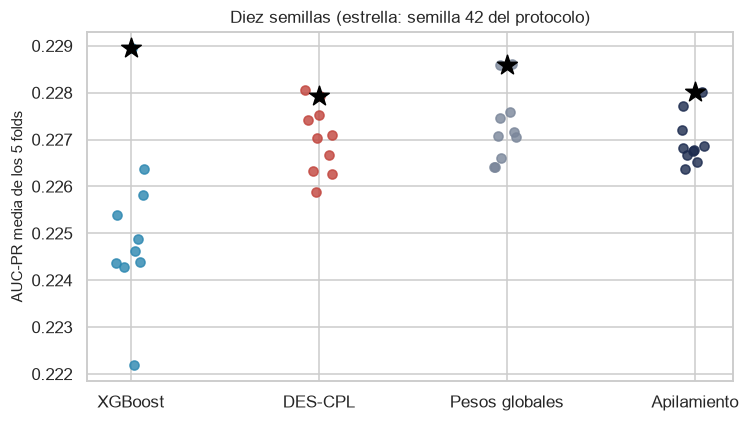

In [10]:
fig, eje = plt.subplots(figsize=(7, 4))
for i, (m, color) in enumerate([("xgboost", "#2A86B0"), ("DES-CPL", "#C1443C"),
                                ("Pesos globales (Brier)", "#7A869A"), ("Apilamiento logístico", "#1B2A4E")]):
    valores = por_semilla[m]
    eje.scatter(np.full(len(valores), i) + np.random.default_rng(i).uniform(-0.08, 0.08, len(valores)),
                valores, color=color, alpha=0.8)
    eje.scatter([i], [por_semilla.loc[42, m]], marker="*", s=180, color="black", zorder=3)
eje.set_xticks(range(4), ["XGBoost", "DES-CPL", "Pesos globales", "Apilamiento"])
eje.set_ylabel("AUC-PR media de los 5 folds")
eje.set_title("Diez semillas (estrella: semilla 42 del protocolo)")
plt.tight_layout()
plt.show()

**Lectura.**
- **La comparación confirmatoria cayó en el extremo.** Con la semilla 42, la que fijó el protocolo, XGBoost obtuvo 0.2290, su mejor valor de las diez semillas. Con las otras nueve queda entre 0.2222 y 0.2264, y su media es 0.2251.
- **DES-CPL es más estable.** Su desviación entre semillas es de 0.0007, menos de la mitad que la de XGBoost (0.0017), y su media es 0.2270. Queda por encima de XGBoost en 9 de las 10 semillas. Los pesos globales y el apilamiento son igual de estables y tienen la misma media: la estabilidad viene de combinar, no de la parte local.
- **Dos lecturas válidas.** La comparación confirmatoria (capítulo 13), con una sola semilla, no encontró diferencias, y ese resultado se mantiene: el protocolo fijó la semilla 42 antes de ver los resultados, y cambiar de semilla después sería buscar el resultado. Lo que añade este estudio es que la ventaja de XGBoost en esa comparación dependía en parte de la semilla, y que, promediando el azar, DES-CPL rinde algo más y con menos variabilidad.
- **Alcance.** Es un resultado exploratorio. El Wilcoxon por semillas no corrige que las semillas compartan los mismos folds, y la diferencia media, de unas dos milésimas, es del mismo orden que la incertidumbre entre folds.

## 16.5. Sensibilidad a los hiperparámetros

En el fold 0, con las predicciones ya calculadas, se evaluó DES-CPL en la rejilla completa $\lambda \times k$, con la $\tau$ y la poda elegidas, y en un barrido de $\tau$ con el $k$ y el $\lambda$ elegidos ($k = 30$, $\lambda = 1$, $\tau = 10^{-4}$, 4 modelos). Se reporta el AUC-PR en el conjunto de selección, que es lo que vio la búsqueda, y en el fold de evaluación.

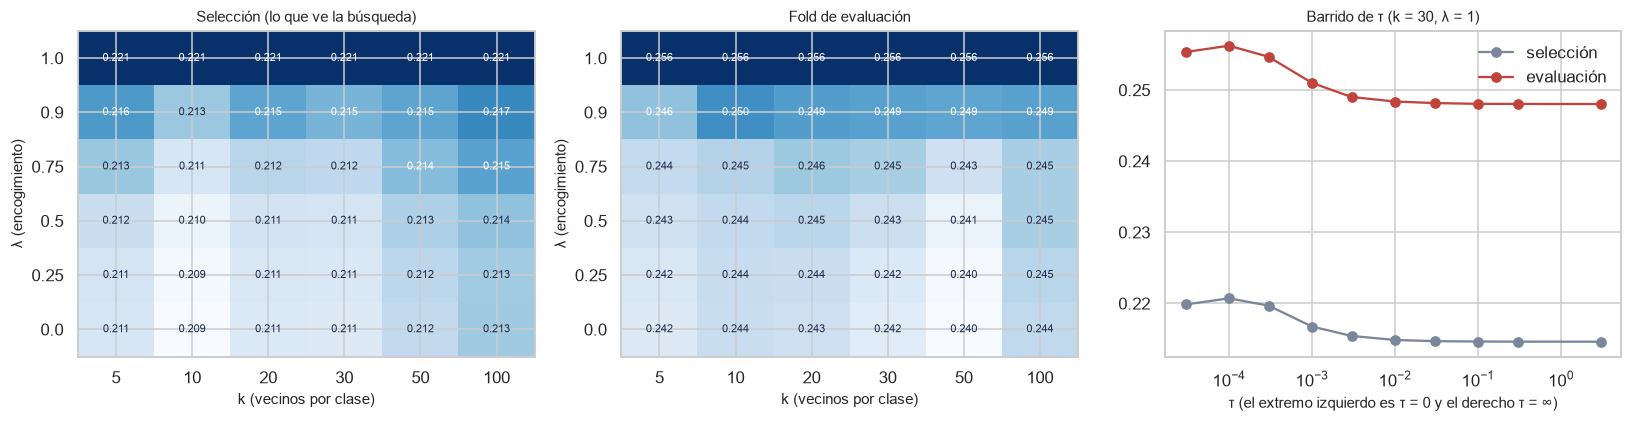

Rango del AUC-PR de evaluación en toda la rejilla λ × k: 0.2397 a 0.2562


In [11]:
sens = pd.read_csv(RESULTADOS / "sensibilidad_des_cpl.csv")
rejilla = sens.query("barrido == 'lambda x k'")
fig, ejes = plt.subplots(1, 3, figsize=(15, 4))
for eje, col, titulo in [(ejes[0], "auc_pr_seleccion", "Selección (lo que ve la búsqueda)"),
                         (ejes[1], "auc_pr", "Fold de evaluación")]:
    mapa = rejilla.pivot_table(index="lambda", columns="k", values=col)
    imagen = eje.imshow(mapa, cmap="Blues", aspect="auto", origin="lower")
    eje.set_xticks(range(mapa.shape[1]), mapa.columns)
    eje.set_yticks(range(mapa.shape[0]), mapa.index)
    eje.set_xlabel("k (vecinos por clase)")
    eje.set_ylabel("λ (encogimiento)")
    eje.set_title(titulo, fontsize=10)
    for (i, j), v in np.ndenumerate(mapa.to_numpy()):
        eje.text(j, i, f"{v:.3f}", ha="center", va="center", fontsize=7,
                 color="white" if v > mapa.to_numpy().mean() else "#1B2A4E")
barrido = sens.query("barrido == 'tau'").copy()
barrido["tau_eje"] = barrido["tau"].replace({0.0: 3e-5, np.inf: 3.0})
ejes[2].plot(barrido["tau_eje"], barrido["auc_pr_seleccion"], marker="o", color="#7A869A", label="selección")
ejes[2].plot(barrido["tau_eje"], barrido["auc_pr"], marker="o", color="#C1443C", label="evaluación")
ejes[2].set_xscale("log")
ejes[2].set_xlabel("τ (el extremo izquierdo es τ = 0 y el derecho τ = ∞)")
ejes[2].set_title("Barrido de τ (k = 30, λ = 1)", fontsize=10)
ejes[2].legend()
plt.tight_layout()
plt.show()
print("Rango del AUC-PR de evaluación en toda la rejilla λ × k:",
      f"{rejilla['auc_pr'].min():.4f} a {rejilla['auc_pr'].max():.4f}")

**Lectura.**
- **λ manda.** Con $\lambda = 1$ el valor de $k$ no importa, porque la competencia es la global y no usa vecinos. Al bajar $\lambda$, el AUC-PR cae de forma monótona, y la caída es la misma en el conjunto de selección y en el de evaluación: la búsqueda no eligió $\lambda = 1$ por sobreajuste.
- **k casi no importa.** Con $\lambda$ fijo, $k$ mueve el resultado menos de 0.005.
- **τ importa poco.** $\tau$ pequeña ($\le 3 \cdot 10^{-4}$, que concentra el peso en el mejor modelo según el Brier global) supera a $\tau$ grande (el promedio de los 4 modelos podados) en menos de 0.01. Entre $\tau = 0$ y $\tau = 10^{-4}$ la diferencia es mínima.

Esto confirma, con la rejilla completa, lo que el capítulo 15 explicó con la proposición 4: la parte local de DES-CPL no aporta ordenamiento en estos datos.

## 16.6. Interpretabilidad: SHAP de DES-CPL comparado con XGBoost

La guía pide aplicar SHAP al modelo original. Se usan los valores de Shapley por permutaciones antitéticas de `src/explicacion.py`, sobre las 38 variables **originales**, con:
- los mismos 150 casos de prueba para todos los modelos;
- el mismo conjunto de fondo de 20 encuentros;
- 8 permutaciones por caso.

Así las importancias de DES-CPL y de los benchmarks se comparan directamente. Los valores los calcula `experiments/artefacto_des_cpl.py` sobre el modelo serializado y quedan en `artifacts/shap_global.parquet`.

La importancia global de cada variable es la media del valor absoluto de su contribución.

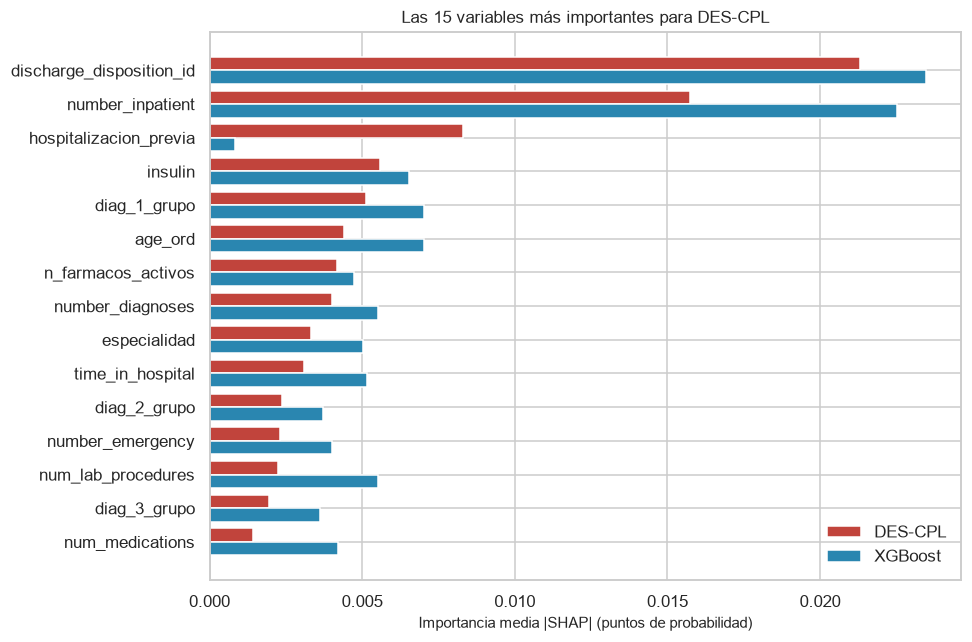

modelo,des_cpl,xgboost,random_forest,logistica
modelo,,,,
des_cpl,1.00,0.92,0.94,0.73
xgboost,0.92,1.00,0.88,0.62
random_forest,0.94,0.88,1.00,0.69
logistica,0.73,0.62,0.69,1.00


Spearman DES-CPL vs XGBoost: 0.92
Variables compartidas entre las 15 más importantes de cada uno: 14/15
Cinco primeras de DES-CPL: discharge_disposition_id, number_inpatient, hospitalizacion_previa, insulin, diag_1_grupo
Cinco primeras de XGBoost: discharge_disposition_id, number_inpatient, diag_1_grupo, age_ord, insulin
Parte de la importancia total en las 5 primeras: des_cpl 58%, xgboost 51%, random_forest 57%, logistica 50%


WindowsPath('C:/Users/joshu/Documents/GitHub/Diabetes_ProyectoML_202630/results/shap_importancia_global.csv')

In [12]:
ARTEFACTOS = RAIZ / "artifacts"
shap_largo = pd.read_parquet(ARTEFACTOS / "shap_global.parquet")
importancia = (shap_largo.assign(abs_shap=shap_largo["shap"].abs())
               .groupby(["modelo", "variable"])["abs_shap"].mean().unstack("modelo"))
comparar = ["des_cpl", "xgboost", "random_forest", "logistica"]
importancia = importancia[[m for m in comparar if m in importancia]]
top = importancia["des_cpl"].sort_values(ascending=False).head(15).index

fig, eje = plt.subplots(figsize=(9, 6))
y = np.arange(len(top))
eje.barh(y - 0.2, importancia.loc[top, "des_cpl"], height=0.4, color="#C1443C", label="DES-CPL")
eje.barh(y + 0.2, importancia.loc[top, "xgboost"], height=0.4, color="#2A86B0", label="XGBoost")
eje.set_yticks(y, top)
eje.invert_yaxis()
eje.set_xlabel("Importancia media |SHAP| (puntos de probabilidad)")
eje.set_title("Las 15 variables más importantes para DES-CPL")
eje.legend()
plt.tight_layout()
plt.show()

correlacion = importancia.corr(method="spearman")
display(correlacion.round(2))
top_xgb = importancia["xgboost"].sort_values(ascending=False).head(15).index
comunes = len(set(top) & set(top_xgb))
print(f"Spearman DES-CPL vs XGBoost: {correlacion.loc['des_cpl', 'xgboost']:.2f}")
print(f"Variables compartidas entre las 15 más importantes de cada uno: {comunes}/15")
print("Cinco primeras de DES-CPL:", ", ".join(top[:5]))
print("Cinco primeras de XGBoost:", ", ".join(top_xgb[:5]))
concentracion = importancia.apply(lambda c: c.nlargest(5).sum() / c.sum())
print("Parte de la importancia total en las 5 primeras:",
      ", ".join(f"{m} {v:.0%}" for m, v in concentracion.items()))
guardar_resultado(importancia, "shap_importancia_global")

**Lectura.**
- **Las mismas variables.** La correlación de Spearman entre las importancias de DES-CPL y las de XGBoost es 0.92, y comparten 14 de sus 15 variables más importantes. Encabezan ambas listas el destino al alta (`discharge_disposition_id`) y las hospitalizaciones del año anterior (`number_inpatient`), seguidas por la insulina y el grupo del diagnóstico principal, como en el capítulo 10. Es lo esperable: DES-CPL combina cuatro modelos, entre ellos XGBoost y Random Forest, y con $\lambda = 0.9$ sus pesos son casi globales.
- **Más parecido a Random Forest que a XGBoost.** La correlación con Random Forest es todavía mayor (0.94), y su tercera variable es `hospitalizacion_previa`, una versión binaria de `number_inpatient` que XGBoost apenas usa. DES-CPL hereda la forma de explicar del bosque.
- **No más repartida.** Las cinco primeras variables reúnen el 58 % de la importancia en DES-CPL, frente al 51 % en XGBoost y el 57 % en Random Forest. Combinar modelos no diluye la dependencia de las variables de utilización previa: los cuatro modelos la comparten, así que el promedio la conserva.
- **Ninguna variable propia.** La explicación no revela variables que solo use DES-CPL. Es coherente con el diagnóstico del capítulo 13: la información disponible es la misma para todos los modelos, y combinarlos no la amplía.

## 16.7. Equidad de DES-CPL por subgrupo

El capítulo 7 midió la equidad de la línea base con el criterio de **igualdad de oportunidad**. Para cada grupo calculó la cobertura: la proporción de sus readmisiones que quedan dentro del 10 % de mayor riesgo. Aquí se aplica el mismo criterio, con la misma capacidad del 10 %, a DES-CPL y a XGBoost en el conjunto de prueba.

- La **cobertura relativa** divide la cobertura del grupo entre la global: 1 significa que el grupo recibe su parte justa, y menos de 1, que sus readmisiones se pasan por alto más que las del resto.
- Se reportan solo los grupos con al menos 100 encuentros. El capítulo 7 usó 200, pero el conjunto de prueba es cuatro veces más pequeño que el de entrenamiento.

In [13]:
roles = json.loads((RAIZ / "data" / "processed" / "roles_variables.json").read_text(encoding="utf-8"))
prueba = pd.read_parquet(RAIZ / "data" / "processed" / "diabetes_test.parquet")
pred = pd.read_parquet(ARTEFACTOS / "predicciones_prueba.parquet")
objetivo = pred["y_real"].to_numpy()
# Las predicciones se guardaron en el orden de diabetes_test.parquet.
assert (objetivo == prueba[roles["objetivo"]].to_numpy()).all()
etiquetas_edad = {int(k): v for k, v in roles["etiquetas_edad"].items()}
CAPACIDAD = 0.10   # la misma del capítulo 7

filas = []
for modelo in ["des_cpl", "xgboost"]:
    p = pred[modelo].to_numpy()
    seleccionado = p >= np.quantile(p, 1 - CAPACIDAD)
    cobertura_global = (seleccionado & (objetivo == 1)).sum() / objetivo.sum()
    for atributo in ["race", "gender", "age_ord"]:
        columna = prueba[atributo]
        if atributo == "age_ord":
            columna = columna.map(etiquetas_edad)
        valores = columna.to_numpy()
        for grupo in sorted(pd.unique(valores), key=str):
            m = valores == grupo
            if m.sum() < 100:
                continue
            real = objetivo[m]
            cobertura = (seleccionado[m] & (real == 1)).sum() / max(real.sum(), 1)
            precision = (seleccionado[m] & (real == 1)).sum() / max(seleccionado[m].sum(), 1)
            filas.append({"modelo": modelo, "atributo": atributo, "grupo": grupo,
                          "encuentros": int(m.sum()), "tasa real (%)": 100 * real.mean(),
                          "cobertura (%)": 100 * cobertura, "precisión (%)": 100 * precision,
                          "cobertura relativa": cobertura / cobertura_global})
equidad = pd.DataFrame(filas)
guardar_resultado(equidad, "equidad_des_cpl_prueba")
tabla_equidad = equidad.pivot_table(index=["atributo", "grupo"], columns="modelo",
                                    values=["cobertura relativa", "precisión (%)"]).round(2)
tabla_equidad.insert(0, "encuentros", equidad.drop_duplicates(["atributo", "grupo"])
                     .set_index(["atributo", "grupo"])["encuentros"])
display(tabla_equidad)
ancho = equidad.pivot_table(index=["atributo", "grupo"], columns="modelo", values="cobertura relativa")
diferencia = (ancho["des_cpl"] - ancho["xgboost"]).abs()
print(f"Mayor diferencia de cobertura relativa entre DES-CPL y XGBoost: {diferencia.max():.2f} "
      f"({' / '.join(map(str, diferencia.idxmax()))})")
for modelo in ["des_cpl", "xgboost"]:
    peor = ancho[modelo].idxmin()
    print(f"Menor cobertura relativa de {modelo}: {ancho[modelo].min():.2f} ({' / '.join(map(str, peor))})")

encuentros cobertura relativa         precisión (%)        
modelo                                         des_cpl xgboost       des_cpl xgboost
atributo grupo                                                                      
age_ord  [10-20)                114               0.60    1.19         20.00   40.00
         [20-30)                312               1.73    1.86         27.91   31.71
         [30-40)                753               1.44    1.38         29.09   29.25
         [40-50)               1903               1.24    1.23         23.23   24.73
         [50-60)               3426               1.09    1.04         32.89   34.05
         [60-70)               4505               1.05    1.03         26.02   27.53
         [70-80)               5011               0.94    0.99         27.15   26.62
         [80-90)               3263               0.76    0.81         25.08   23.87
         [90-100)               545               0.75    0.49         32.61   22.73
gender   Female               10531               1.01    0.96         28.19   27.69
         Male                  9336               0.99    1.05         26.29   27.16
race     AfricanAmerican       3758               1.02    0.94         24.75   24.93
         Asian                  114               0.38    0.38         20.00   25.00
         Caucasian            14826               1.02    1.03         28.16   27.78
         Hispanic               378               1.17    1.35         27.27   34.15
         No informada           463               0.34    0.45         21.43   33.33
         Other                  328               0.49    0.61         18.18   29.41

Mayor diferencia de cobertura relativa entre DES-CPL y XGBoost: 0.59 (age_ord / [10-20))
Menor cobertura relativa de des_cpl: 0.34 (race / No informada)
Menor cobertura relativa de xgboost: 0.38 (race / Asian)


**Lectura.**
- **Sexo: paridad.** La cobertura relativa es 1.01 en mujeres y 0.99 en hombres con DES-CPL, algo más pareja que con XGBoost (0.96 y 1.05).
- **Grupos grandes: sin diferencias.** En los afroamericanos, los caucásicos y las edades de 40 a 80 años, las coberturas de los dos modelos difieren a lo sumo en 0.08.
- **Grupos pequeños: las mismas brechas del capítulo 7.** Las coberturas más bajas aparecen, con los dos modelos, en los encuentros sin raza registrada (0.34 con DES-CPL, 0.45 con XGBoost), en «Other» (0.49 y 0.61) y en «Asian» (0.38 en ambos). El capítulo 7 encontró las mismas brechas en la línea base (0.36 sin raza registrada y 0.69 en «Other»). Son grupos con menos utilización previa registrada, la información en que se apoyan todos los modelos (sección 16.6). Ningún combinador lo corrige, porque la información que falta no la tiene ningún modelo base.
- **Las diferencias entre modelos son de pocos casos.** La mayor diferencia está en los pacientes de 10 a 20 años: 0.60 con DES-CPL y 1.19 con XGBoost. Pero ese grupo tiene 114 encuentros y, con la prevalencia del 11 %, poco más de una decena de readmisiones, así que la brecha equivale a muy pocos pacientes. Lo mismo pasa en sentido contrario de 90 a 100 años (0.75 contra 0.49). Con ese tamaño no se puede afirmar que un modelo trate mejor a esos grupos que el otro.
- **Veredicto.** DES-CPL no introduce sesgos nuevos ni corrige los existentes: hereda las brechas de los datos. Para un uso real se mantiene la recomendación de la ficha del modelo: monitorear la cobertura por grupo, sobre todo en los encuentros sin raza registrada, y revisar el umbral.

## 16.8. Presupuesto y tiempos

La guía (sección 6.2) pide reportar el hardware, el tiempo de entrenamiento y de inferencia, y la memoria de cada modelo. Todos los tiempos son de un mismo equipo: 4 núcleos físicos y 8 lógicos, sin GPU, con `N_JOBS = 4`. Los produce `experiments/artefacto_des_cpl.py` a partir de los registros de cada experimento.

| Columna | Qué mide |
|---|---|
| `evaluaciones` | Configuraciones de hiperparámetros probadas: 60 para todos (equidad de la comparación) |
| `busqueda_min_por_fold` | Tiempo de la búsqueda de hiperparámetros por fold externo. En DES-CPL es su búsqueda propia, medida sobre el entrenamiento completo |
| `ajuste_final_s` | Ajuste con todo el entrenamiento. En DES-CPL incluye reentrenar 4 veces cada modelo base: 3 pliegues para el conjunto de selección y el modelo final |
| `inferencia_ms_por_caso` | Tiempo de predicción por encuentro |
| `artefacto_mb` | Tamaño del modelo serializado, con compresión 3, como medida de la memoria que ocupa |

In [14]:
presupuesto = pd.read_csv(RESULTADOS / "presupuesto_tiempos.csv").set_index("modelo")
display(presupuesto.round(3))
d = presupuesto.loc["des_cpl"]
print(f"DES-CPL: búsqueda propia {d['busqueda_min_por_fold']:.1f} min; conjunto de selección "
      f"{d['conjunto_seleccion_min_por_fold']:.1f} min por fold; ajuste final {d['ajuste_final_s'] / 60:.1f} min; "
      f"inferencia {d['inferencia_ms_por_caso'] / presupuesto.loc['xgboost', 'inferencia_ms_por_caso']:.0f} veces "
      f"la de XGBoost; {d['artefacto_mb']:.1f} MB")

,familia,evaluaciones,busqueda_min_por_fold,ajuste_final_s,inferencia_ms_por_caso,artefacto_mb,conjunto_seleccion_min_por_fold
modelo,,,,,,,
arbol,Modelo base,60,4.827,9.448,0.024,0.011,NaN
bayes,Modelo base,60,4.531,7.456,0.028,0.008,NaN
knn,Modelo base,60,8.061,6.569,0.825,4.802,NaN
logistica,Modelo base,60,6.308,10.896,0.021,0.004,NaN
random_forest,Modelo base,60,19.614,84.874,0.051,30.134,NaN
svm,Modelo base,60,4.812,9.230,0.020,0.008,NaN
xgboost,Modelo base,60,13.425,92.270,0.034,1.205,NaN
catboost,Estado del arte,60,17.905,13.740,0.020,NaN,NaN
lightgbm,Estado del arte,60,4.838,4.551,0.023,NaN,NaN


DES-CPL: búsqueda propia 8.1 min; conjunto de selección 5.3 min por fold; ajuste final 6.8 min; inferencia 13 veces la de XGBoost; 12.9 MB


**Lectura.**
- **La búsqueda es barata.** Las 60 evaluaciones propias de DES-CPL tardan unos 8 minutos, menos que las de Random Forest, CatBoost o XGBoost. Es lo que predijo la complejidad del capítulo 15: cada evaluación solo consulta vecinos y combina probabilidades, sin reentrenar nada.
- **Lo caro es el conjunto de selección.** Construirlo exige reentrenar cada modelo base en 3 pliegues; con el modelo final, son 4 ajustes por modelo. Es el costo de cualquier ensamble apilado con predicciones fuera de pliegue, y el protocolo lo declara por separado de las 60 evaluaciones. Por eso el ajuste final de DES-CPL (unos 7 minutos) es varias veces el de un modelo individual.
- **Inferencia.** Es un orden de magnitud más lenta que la de un modelo individual, porque hay que predecir con 16 modelos (4 finales y 12 de pliegue, estos últimos para ubicar la consulta en el espacio de perfiles) y buscar vecinos. Aun así queda por debajo de un milisegundo por paciente, de sobra para la predicción en vivo del dashboard.
- **Memoria.** El artefacto ocupa 12.9 MB, menos que el Random Forest (30.1 MB), pero mucho más que XGBoost (1.2 MB): guarda 16 modelos y el conjunto de selección completo para buscar vecinos.

## 16.9. Pruebas complementarias: McNemar y t bayesiana

El protocolo fijó tres pruebas confirmatorias: Friedman con Nemenyi, Nadeau-Bengio y DeLong (capítulo 13). La guía de redacción del artículo pide además, para clasificación, la prueba exacta de McNemar y una prueba bayesiana con región de equivalencia práctica. Se añadieron **después** de congelar el protocolo, así que son **complementarias**: no pueden sustentar R3 por sí solas (guía, sección 6.1). Se calculan aquí con las mismas predicciones y los mismos pliegues, sin entrenar nada; las funciones están en `src/estadistica.py`, con sus pruebas en `tests/test_estadistica.py`.

**McNemar exacta (conjunto de prueba).** Compara las *decisiones* de dos modelos con el umbral operativo, que marca al 15 % de mayor riesgo de cada uno. Solo cuentan los encuentros discordantes:
- $n_{01}$: DES-CPL acierta y el benchmark falla;
- $n_{10}$: DES-CPL falla y el benchmark acierta.

Si los dos modelos fueran igual de buenos, cada discordante caería de un lado o del otro con probabilidad 1/2, así que $n_{01} \sim \text{Binomial}(n_{01} + n_{10}, 1/2)$. La versión exacta usa esa binomial.

**t bayesiana correlacionada (pliegues externos).** Es la versión bayesiana de Nadeau-Bengio (Corani y Benavoli, 2015). La posterior de la diferencia media de AUC-PR es una $t$ de Student con 4 grados de libertad, centrada en la media de las cinco diferencias y con la misma varianza corregida por el solapamiento de los entrenamientos. En lugar de un valor $p$ da tres probabilidades, con una región de equivalencia práctica (ROPE) de $\pm 0.005$, el umbral de relevancia que fijó el estudio de convergencia del capítulo 12:
- **mejor:** la diferencia supera $+0.005$;
- **equivalente:** queda dentro de $\pm 0.005$;
- **peor:** queda por debajo de $-0.005$.

In [15]:
from src.estadistica import prueba_mcnemar_exacta, t_bayesiana_correlacionada

ROPE = 0.005          # umbral de relevancia práctica del capítulo 12
CAPACIDAD_OPERATIVA = 0.15

pliegues = principal.pivot_table(index="fold", columns="método", values="auc_pr")
pred_prueba = pd.read_csv(RESULTADOS / "prueba_predicciones.csv")
y_prueba = pred_prueba["y"].to_numpy()

def marcar(probabilidades):
    # Umbral operativo: el percentil 85 de las puntuaciones del propio modelo.
    return probabilidades >= np.quantile(probabilidades, 1 - CAPACIDAD_OPERATIVA)

decision_des = marcar(pred_prueba["DES-CPL"].to_numpy())
filas = []
for b in BENCHMARKS:
    mc = prueba_mcnemar_exacta(y_prueba, decision_des, marcar(pred_prueba[b].to_numpy()))
    bay = t_bayesiana_correlacionada(pliegues["DES-CPL"] - pliegues[b], rope=ROPE)
    filas.append({"benchmark": b, "n01 (DES-CPL acierta)": mc["n01"], "n10 (benchmark acierta)": mc["n10"],
                  "p McNemar": mc["p"], "P(mejor)": bay["mejor"], "P(equivalente)": bay["equivalente"],
                  "P(peor)": bay["peor"]})
complementarias = pd.DataFrame(filas).set_index("benchmark")
complementarias.insert(3, "p McNemar (Holm)", correccion_holm(complementarias["p McNemar"].to_numpy()))
guardar_resultado(complementarias, "pruebas_complementarias")
display(complementarias.round(3))

significativos = complementarias.index[complementarias["p McNemar (Holm)"] < 0.05].tolist()
print("McNemar significativo tras Holm frente a:", ", ".join(significativos) or "ninguno")
for etiqueta, columna in [("mejor", "P(mejor)"), ("equivalente", "P(equivalente)")]:
    print(f"Mayor probabilidad posterior de '{etiqueta}':",
          ", ".join(complementarias.index[complementarias[["P(mejor)", "P(equivalente)", "P(peor)"]].idxmax(axis=1) == columna]))

,n01 (DES-CPL acierta),n10 (benchmark acierta),p McNemar,p McNemar (Holm),P(mejor),P(equivalente),P(peor)
benchmark,,,,,,,
logistica,583,567,0.658,1.000,0.973,0.023,0.004
bayes,941,867,0.086,0.602,0.998,0.002,0.001
knn,929,805,0.003,0.025,0.997,0.003,0.001
arbol,569,234,0.000,0.000,0.985,0.011,0.004
random_forest,376,354,0.437,1.000,0.326,0.672,0.002
xgboost,159,175,0.412,1.000,0.100,0.715,0.185
svm,434,412,0.470,1.000,0.948,0.047,0.005
lightgbm,266,246,0.401,1.000,0.283,0.657,0.059
catboost,303,291,0.652,1.000,0.045,0.881,0.074


McNemar significativo tras Holm frente a: knn, arbol
Mayor probabilidad posterior de 'mejor': logistica, bayes, knn, arbol, svm
Mayor probabilidad posterior de 'equivalente': random_forest, xgboost, lightgbm, catboost


**Lectura.**
- **Frente a los mejores modelos, nada cambia.** Con XGBoost, CatBoost y LightGBM, McNemar no encuentra diferencia en las decisiones ($p_{\text{Holm}} = 1$), y la prueba bayesiana da como lo más probable la **equivalencia práctica**: 0.72, 0.88 y 0.66. Frente a XGBoost, la probabilidad de que DES-CPL sea peor (0.18) supera incluso a la de que sea mejor (0.10).
- **Frente a los modelos simples, depende de la prueba.** McNemar solo es significativo tras Holm frente a $k$-NN y el árbol. La prueba bayesiana da más de 0.95 de probabilidad de una mejora práctica frente a Naive Bayes, $k$-NN, el árbol y la regresión logística, y frente a Random Forest domina la equivalencia (0.67).
- **Por qué McNemar detecta menos.** Solo mira qué encuentros cambian de lado del umbral, y entre modelos tan correlacionados son pocos: frente a XGBoost, 159 contra 175 de casi veinte mil. Descarta toda la información de ordenamiento que sí usan el AUC-PR y DeLong.
- **Conclusión.** Las dos pruebas confirman el veredicto del capítulo 13: no hay evidencia de que DES-CPL supere al mejor benchmark, y R3 sigue sin cumplirse.

## 16.10. Síntesis de la evaluación ampliada

| Pregunta | Respuesta |
|---|---|
| ¿Se generaliza el comportamiento a otros dominios? | Sí. En los tres conjuntos adicionales DES-CPL queda en la cabeza, junto a los ensambles estáticos, y por delante de todos los benchmarks individuales en rango medio. |
| ¿Supera al mejor benchmark de cada conjunto? | Solo en CDC, y sin significancia. La condición 4 del protocolo no se cumple. |
| ¿Es robusto? | Más que XGBoost, que pierde entre 1.5 y 2 veces más con ruido en las etiquetas, menos prevalencia y menos datos. Random Forest y la regresión logística pierden aún menos, desde un punto de partida más bajo. |
| ¿Es estable frente a la semilla? | Sí, como los otros combinadores y más que XGBoost. La comparación confirmatoria cayó en la mejor semilla de XGBoost. |
| ¿Es sensible a sus hiperparámetros? | Solo a $\lambda$, y en la misma dirección en selección y en evaluación. |
| ¿En qué variables se apoya? | En las mismas que XGBoost (Spearman 0.92, 14 de 15 variables principales en común), sobre todo el destino al alta y las hospitalizaciones previas (sección 16.6). |
| ¿Trata distinto a algún grupo? | No más que XGBoost. Hay paridad por sexo; las brechas en los encuentros sin raza registrada, «Other» y «Asian» son las del capítulo 7 y vienen de los datos (sección 16.7). |
| ¿Cambian el veredicto McNemar y la $t$ bayesiana? | No. Frente a XGBoost, CatBoost y LightGBM, McNemar no encuentra diferencias y la prueba bayesiana da como lo más probable la equivalencia práctica (sección 16.9). |
| ¿Cuánto cuesta? | Su búsqueda es más barata que la de los modelos de árboles; el costo está en el conjunto de selección (4 ajustes por modelo base) y en una inferencia unas 13 veces más lenta que la de XGBoost, aún por debajo de 1 ms por caso. |

**Veredicto.** La evaluación ampliada no cambia el de R3: DES-CPL no supera de forma significativa al mejor benchmark, y el tope de nota sigue en 4.0. Sí cambia la caracterización del modelo: es un combinador **robusto y estable**, que en ningún conjunto queda lejos del mejor método y que nunca depende de acertar cuál es el mejor modelo individual, que cambia de un dominio a otro.